## K-Nearest Neighbors (KNN) Classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from mlxtend.plotting import plot_decision_regions
from sklearn.decomposition import PCA

### 1. Load and Explore Data

In [2]:
# Load the dataset
df = pd.read_csv('/content/sonar.csv', header=None)

# Display the first few rows
print("First 5 rows of the dataset:")
display(df.head())

# Display basic information about the dataset
print("\nDataset Info:")
df.info()

# Display descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# Check the distribution of the target variable (last column)
print("\nTarget variable distribution:")
display(df[60].value_counts())

First 5 rows of the dataset:


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       208 non-null    float64
 1   1       208 non-null    float64
 2   2       208 non-null    float64
 3   3       208 non-null    float64
 4   4       208 non-null    float64
 5   5       208 non-null    float64
 6   6       208 non-null    float64
 7   7       208 non-null    float64
 8   8       208 non-null    float64
 9   9       208 non-null    float64
 10  10      208 non-null    float64
 11  11      208 non-null    float64
 12  12      208 non-null    float64
 13  13      208 non-null    float64
 14  14      208 non-null    float64
 15  15      208 non-null    float64
 16  16      208 non-null    float64
 17  17      208 non-null    float64
 18  18      208 non-null    float64
 19  19      208 non-null    float64
 20  20      208 non-null    float64
 21  21      208 non-null    

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,...,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,0.029164,0.038437,0.043832,0.053892,0.075202,0.104570,0.121747,0.134799,0.178003,0.208259,...,0.016069,0.013420,0.010709,0.010941,0.009290,0.008222,0.007820,0.007949,0.007941,0.006507
std,0.022991,0.032960,0.038428,0.046528,0.055552,0.059105,0.061788,0.085152,0.118387,0.134416,...,0.012008,0.009634,0.007060,0.007301,0.007088,0.005736,0.005785,0.006470,0.006181,0.005031
min,0.001500,0.000600,0.001500,0.005800,0.006700,0.010200,0.003300,0.005500,0.007500,0.011300,...,0.000000,0.000800,0.000500,0.001000,0.000600,0.000400,0.000300,0.000300,0.000100,0.000600
25%,0.013350,0.016450,0.018950,0.024375,0.038050,0.067025,0.080900,0.080425,0.097025,0.111275,...,0.008425,0.007275,0.005075,0.005375,0.004150,0.004400,0.003700,0.003600,0.003675,0.003100
50%,0.022800,0.030800,0.034300,0.044050,0.062500,0.092150,0.106950,0.112100,0.152250,0.182400,...,0.013900,0.011400,0.009550,0.009300,0.007500,0.006850,0.005950,0.005800,0.006400,0.005300
75%,0.035550,0.047950,0.057950,0.064500,0.100275,0.134125,0.154000,0.169600,0.233425,0.268700,...,0.020825,0.016725,0.014900,0.014500,0.012100,0.010575,0.010425,0.010350,0.010325,0.008525
max,0.137100,0.233900,0.305900,0.426400,0.401000,0.382300,0.372900,0.459000,0.682800,0.710600,...,0.100400,0.070900,0.039000,0.035200,0.044700,0.039400,0.035500,0.044000,0.036400,0.043900



Target variable distribution:


,count
60,
M,111
R,97


### 2. Data Preprocessing

In [3]:
# Separate features (X) and target (y)
X = df.iloc[:, :-1] # All columns except the last one
y = df.iloc[:, -1]  # The last column

# Encode the target variable (M/R to 0/1)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Shape of X_train_scaled:", X_train_scaled.shape)
print("Shape of X_test_scaled:", X_test_scaled.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train_scaled: (145, 60)
Shape of X_test_scaled: (63, 60)
Shape of y_train: (145,)
Shape of y_test: (63,)


### 3. K-Nearest Neighbors (KNN) Implementation and Tuning

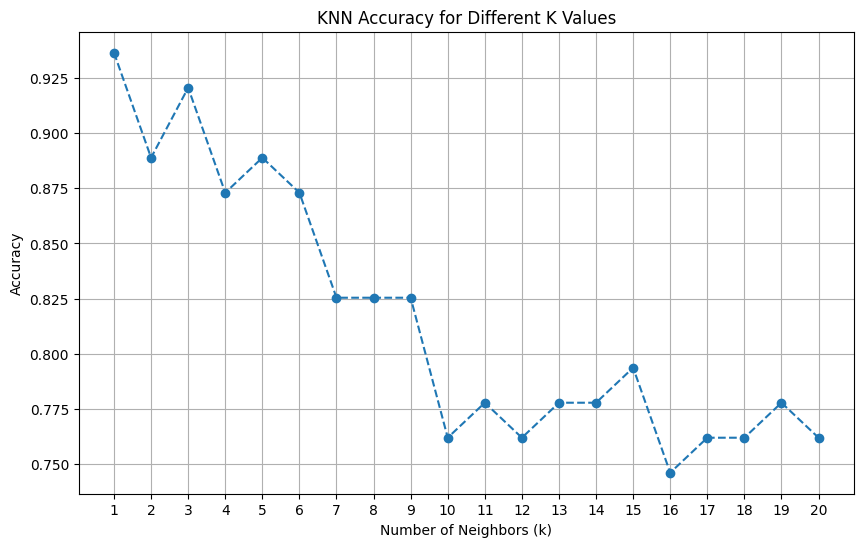

The optimal number of neighbors (k) is: 1

Accuracy with optimal k=1: 0.9365

Confusion Matrix:
[[32  3]
 [ 1 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        35
           1       0.90      0.96      0.93        28

    accuracy                           0.94        63
   macro avg       0.93      0.94      0.94        63
weighted avg       0.94      0.94      0.94        63



In [4]:
# Determine the optimal k value using accuracy on the test set
k_values = range(1, 21) # Test k from 1 to 20
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

# Plotting the accuracy for different k values
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='--')
plt.title('KNN Accuracy for Different K Values')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Find the optimal k
optimal_k = k_values[np.argmax(accuracies)]
print(f"The optimal number of neighbors (k) is: {optimal_k}")

# Train KNN with optimal k
knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k)
knn_optimal.fit(X_train_scaled, y_train)
y_pred_optimal = knn_optimal.predict(X_test_scaled)

# Evaluate the optimal model
print(f"\nAccuracy with optimal k={optimal_k}: {accuracy_score(y_test, y_pred_optimal):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimal))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimal))

### 4. Visualize Decision Boundary (using PCA for dimensionality reduction)

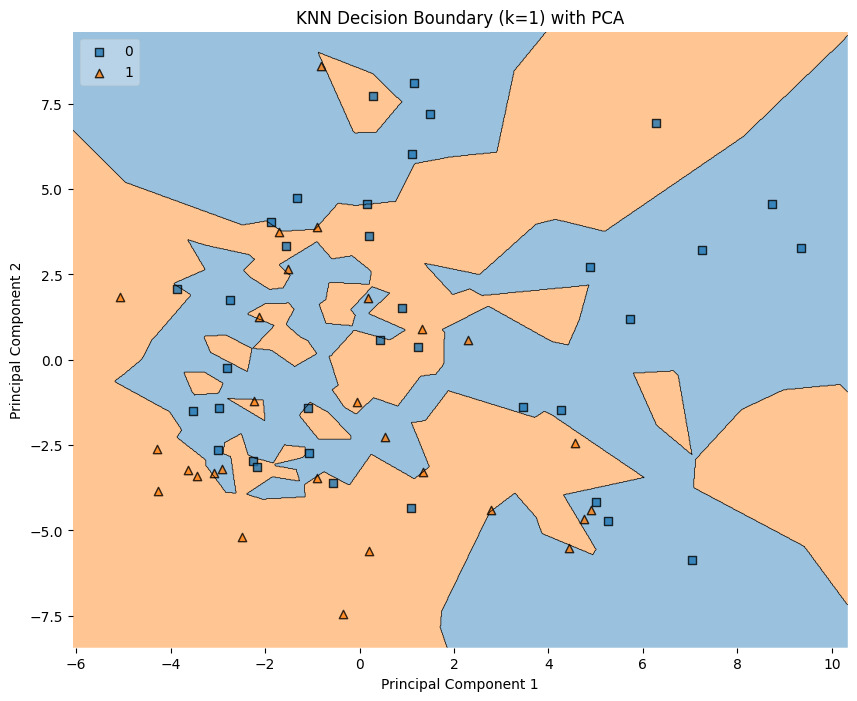

In [5]:
# Apply PCA to reduce dimensionality to 2 components for visualization
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Train KNN on the PCA-transformed training data
knn_pca = KNeighborsClassifier(n_neighbors=optimal_k)
knn_pca.fit(X_train_pca, y_train)

# Plot decision regions
plt.figure(figsize=(10, 8))
plot_decision_regions(X_test_pca, y_test, clf=knn_pca, legend=2)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'KNN Decision Boundary (k={optimal_k}) with PCA')
plt.show()

### 5. Demonstrate the Curse of Dimensionality

Number of features: 2, Accuracy: 0.6032
Number of features: 4, Accuracy: 0.6667
Number of features: 6, Accuracy: 0.7143
Number of features: 8, Accuracy: 0.7619
Number of features: 10, Accuracy: 0.7460
Number of features: 12, Accuracy: 0.8571
Number of features: 14, Accuracy: 0.8413
Number of features: 16, Accuracy: 0.7778
Number of features: 18, Accuracy: 0.7619
Number of features: 20, Accuracy: 0.8571
Number of features: 22, Accuracy: 0.7778
Number of features: 24, Accuracy: 0.7302
Number of features: 26, Accuracy: 0.7619
Number of features: 28, Accuracy: 0.7937
Number of features: 30, Accuracy: 0.8254
Number of features: 32, Accuracy: 0.8571
Number of features: 34, Accuracy: 0.8413
Number of features: 36, Accuracy: 0.8413
Number of features: 38, Accuracy: 0.8571
Number of features: 40, Accuracy: 0.8889
Number of features: 42, Accuracy: 0.9206
Number of features: 44, Accuracy: 0.9365
Number of features: 46, Accuracy: 0.9683
Number of features: 48, Accuracy: 0.9524
Number of features: 

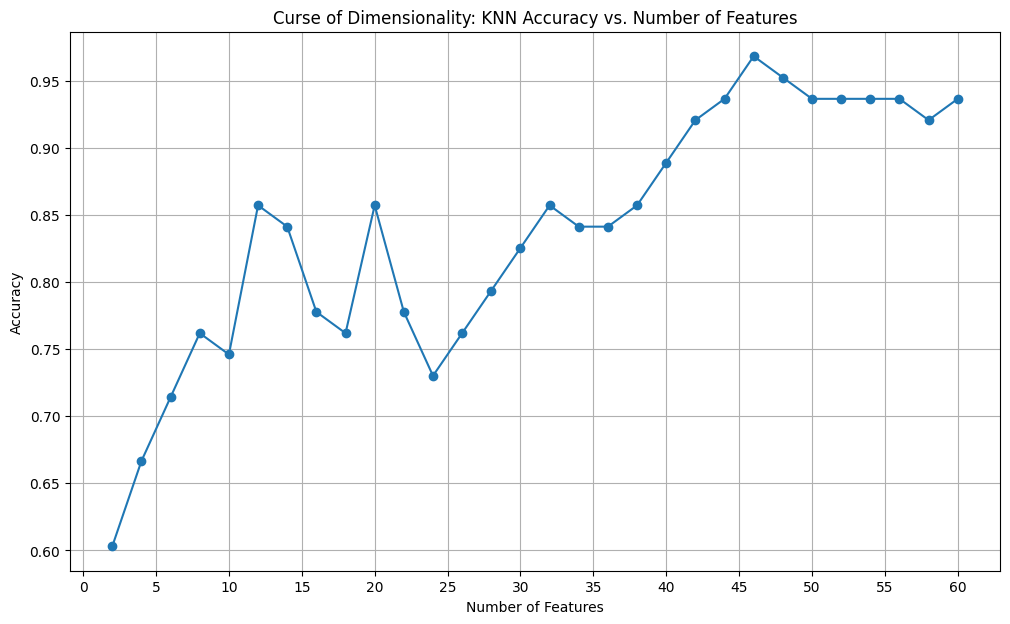

In [6]:
from sklearn.feature_selection import SelectKBest, f_classif

def evaluate_knn_with_n_features(n_features, X_train, X_test, y_train, y_test, optimal_k):
    # Select top n_features using SelectKBest (ANOVA F-value)
    selector = SelectKBest(f_classif, k=n_features)
    X_train_selected = selector.fit_transform(X_train, y_train)
    X_test_selected = selector.transform(X_test)

    # Train KNN with optimal k on selected features
    knn = KNeighborsClassifier(n_neighbors=optimal_k)
    knn.fit(X_train_selected, y_train)
    y_pred = knn.predict(X_test_selected)
    return accuracy_score(y_test, y_pred)

# Range of features to test (e.g., from 2 to 60)
num_features_range = range(2, X_train_scaled.shape[1] + 1, 2)
curse_of_dimensionality_accuracies = []

for n_features in num_features_range:
    accuracy = evaluate_knn_with_n_features(n_features, X_train_scaled, X_test_scaled, y_train, y_test, optimal_k)
    curse_of_dimensionality_accuracies.append(accuracy)
    print(f"Number of features: {n_features}, Accuracy: {accuracy:.4f}")

# Plotting the curse of dimensionality
plt.figure(figsize=(12, 7))
plt.plot(list(num_features_range), curse_of_dimensionality_accuracies, marker='o')
plt.title('Curse of Dimensionality: KNN Accuracy vs. Number of Features')
plt.xlabel('Number of Features')
plt.ylabel('Accuracy')
plt.grid(True)
plt.xticks(np.arange(0, X_train_scaled.shape[1] + 1, 5))
plt.show()

### 6. Visualize Confusion Matrix

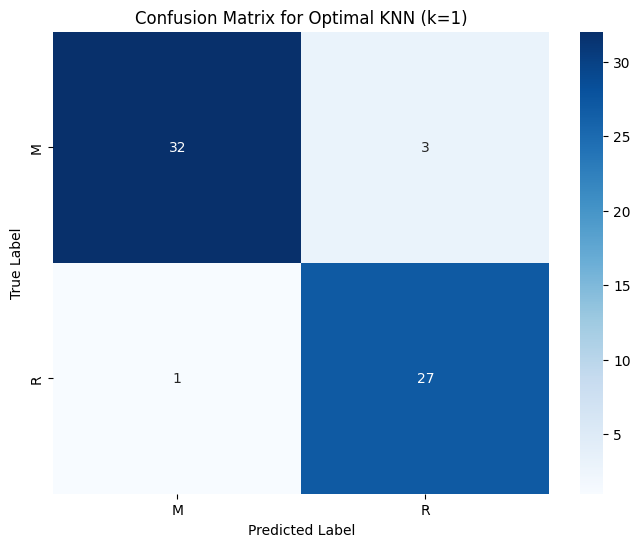

In [7]:
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_optimal)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'Confusion Matrix for Optimal KNN (k={optimal_k})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()